In [1]:
# %%
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as spr
from scipy.sparse.linalg import inv
from scipy.interpolate import RegularGridInterpolator, griddata
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.ticker as mticker
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm, to_rgba
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.dates as mdates


import cmocean
from netCDF4 import Dataset
#from datetime import date, timedelta
import re
import xarray as xr
#from xarray.coders import CFDatetimeCoder

## . . For animation
from matplotlib import animation
from IPython.display import HTML, Image
import geopandas
import rioxarray as rio
from shapely.geometry import mapping, shape
import os
import gc
import pandas as pd
from scipy.interpolate import interp1d
import copy
from pyproj import Transformer
projection = ccrs.SouthPolarStereo()

In [2]:
path = "/Users/rohaizharis/Desktop/Research/Mines/Chapter 1/GRL26"

# %%
IMBIE = geopandas.read_file(path+"/Inputs/ANT_Basins_IMBIE2_v1.6/ANT_Basins_IMBIE2_v1.6.shp", crs="epsg:3031")
scripps = geopandas.read_file(path+"/Inputs/scripps_GL/scripps_antarctica_polygons_v1.shp", crs="epsg:3031")
scripps_gl = scripps.loc[scripps['Id'].astype(int) == 1]
ssb = rio.open_rasterio(path+"/Inputs/AntarcticBasins_BedTypeCode.tif")


/Users/rohaizharis/miniforge3/envs/1d_model/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(
/Users/rohaizharis/miniforge3/envs/1d_model/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(


In [3]:
qs = ['A1','A2','A3','A4']
ds_smb = {q: xr.open_dataset(f'{path}/Inputs/ICESat2/gsfc_ATL15_{q}_0329_10km_005_02.nc') for q in qs}
SMB = (ds_smb['A1']
         .combine_first(ds_smb['A2'])
         .combine_first(ds_smb['A3'])
         .combine_first(ds_smb['A4']))

nt,ny,nx = np.shape(SMB.zsurf)
nt = 22
smb_lag1 = np.zeros((nt,ny,nx),dtype=float)
for i in range(0,nt):
    #difference of adjacent surfaces divided by 0.25, a quarter of the year
    dsmb_dt = (SMB.zsurf[i+1,:,:] - SMB.zsurf[i,:,:])/0.25
    smb_lag1[i,:,:] = dsmb_dt

ds_atl = {q: xr.open_dataset(f'{path}/Inputs/ICESat2/ATL15_{q}_0329_10km_005_02.nc',
                         group='dhdt_lag1') for q in qs}

ATL15 = (ds_atl['A1']
         .combine_first(ds_atl['A2'])
         .combine_first(ds_atl['A3'])
         .combine_first(ds_atl['A4']))


for i in range(0,nt):
    ATL15.dhdt[i,:,:] = ATL15.dhdt[i,:,:] - smb_lag1[i,:,:]


In [4]:
CTCK = xr.open_dataarray(path+"/Outputs/observation/qflux_CTCK.nc")
CTVK = xr.open_dataarray(path+"/Outputs/observation/qflux_CTVK.nc")
VTCK = xr.open_dataarray(path+"/Outputs/observation/qflux_VTCK.nc")
VTVK = xr.open_dataarray(path+"/Outputs/observation/qflux_VTVK.nc")

year = 365.25*24*3600
dims = ["time","y","x"]
numerical_times = np.arange(SMB.time.values[0], SMB.time.values[nt], np.timedelta64(5,'D'))

exfil_numerical = xr.Dataset(
    data_vars={
        "CTCK": (dims,-1000*year*CTCK.values),
        "CTVK": (dims,-1000*year*CTVK.values),
        "VTCK": (dims,-1000*year*VTCK.values),
        "VTVK": (dims,-1000*year*VTVK.values)
    },
    coords={"time":numerical_times, "y": ATL15.y.values, "x": ATL15.x.values},
    attrs={"units": "mm/yr", "description": "Exfiltration rate"}
)
exfil_numerical.rio.write_crs("epsg:3031", inplace=True)
exfil_numerical = exfil_numerical.rio.clip(scripps_gl.geometry.apply(mapping), scripps_gl.crs)

In [5]:
raspoet_mean = xr.open_dataarray(path+"/Inputs/raspoet_mean_v2.nc")
ATL15["raspoet_bmr"] = (['y', 'x'], raspoet_mean.values)
ATL15.rio.write_crs("epsg:3031", inplace=True)

<xarray.Dataset> Size: 84MB
Dimensions:              (time: 28, y: 446, x: 546)
Coordinates:
  * time                 (time) datetime64[ns] 224B 2019-02-15T21:45:00 ... 2...
  * y                    (y) float64 4kB -2.185e+06 -2.175e+06 ... 2.265e+06
  * x                    (x) float64 4kB -2.665e+06 -2.655e+06 ... 2.785e+06
    Polar_Stereographic  int64 8B 0
Data variables:
    ice_area             (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt                 (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt_sigma           (time, y, x) float32 27MB nan nan nan ... nan nan nan
    raspoet_bmr          (y, x) float64 2MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes:
    description:  dhdt_lag1 group includes variables describing height differ...

In [6]:
atl15_x, atl15_y = np.meshgrid(ATL15.x.values, ATL15.y.values)
ssb = ssb.rio.clip(scripps_gl.geometry.apply(mapping), scripps_gl.crs)

ssb_x, ssb_y = np.meshgrid(ssb.x, ssb.y)
ssb_val = ssb.values
ssb_val = ssb_val[0,:,:]
ssb_val[ssb_val < -9000] = np.nan

interp = RegularGridInterpolator(points=[ssb.x.values,ssb.y.values], values=ssb_val.T, method="nearest", fill_value=np.nan, bounds_error = False)
ssb_new = interp((atl15_x, atl15_y))

perm_var = np.zeros_like(ssb_new)
perm_var[ssb_new == 3] = 1e-13      #T1 Basin
perm_var[ssb_new == 2] = 1e-13      #T2 Basin
perm_var[ssb_new == 1] = 1e-13          #Intrabasin volcanics 
perm_var[ssb_new == 0] = 1e-21      #Crystalline
perm_var[ssb_new == -1] = 1e-17     #T2 + C
perm_var[ssb_new == -2] = 1e-18     #T1 and C
perm_var[ssb_new == -3] = 1e-13     #T1 and T2

ATL15["perm_var"] = (['y', 'x'], perm_var)
ATL15.rio.write_crs("epsg:3031", inplace=True)

<xarray.Dataset> Size: 85MB
Dimensions:              (time: 28, y: 446, x: 546)
Coordinates:
  * time                 (time) datetime64[ns] 224B 2019-02-15T21:45:00 ... 2...
  * y                    (y) float64 4kB -2.185e+06 -2.175e+06 ... 2.265e+06
  * x                    (x) float64 4kB -2.665e+06 -2.655e+06 ... 2.785e+06
    Polar_Stereographic  int64 8B 0
Data variables:
    ice_area             (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt                 (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt_sigma           (time, y, x) float32 27MB nan nan nan ... nan nan nan
    raspoet_bmr          (y, x) float64 2MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    perm_var             (y, x) float32 974kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
Attributes:
    description:  dhdt_lag1 group includes variables describing height differ...

In [7]:
thk = xr.open_dataset(path+"/Inputs/Ant_Crust.nc")
thk.rio.write_crs("epsg:3031", inplace=True)
thk = thk.rio.clip(scripps_gl.geometry.apply(mapping), scripps_gl.crs)
thk_val = np.array(thk["Mean_SSB_th"].values)
thk_val[np.isnan(thk_val)] = 0
thk_x, thk_y = np.meshgrid(thk.x, thk.y)
interp = RegularGridInterpolator(points=[thk.x.values,thk.y.values], values=thk_val.T, method="linear", fill_value=np.nan, bounds_error = False)
thk_new = interp((atl15_x, atl15_y))

dz = 100
thk_threshold = copy.deepcopy(thk_new)
thk_threshold[thk_threshold < 300] = np.nan
thk_discr = np.round(thk_threshold / dz) * dz
max_L = thk_discr[~np.isnan(thk_discr)].max()
max_nz = int(max_L/dz) + 2

ATL15["thk_discr"] = (['y', 'x'], thk_discr)
ATL15.rio.write_crs("epsg:3031", inplace=True)


<xarray.Dataset> Size: 87MB
Dimensions:              (time: 28, y: 446, x: 546)
Coordinates:
  * time                 (time) datetime64[ns] 224B 2019-02-15T21:45:00 ... 2...
  * y                    (y) float64 4kB -2.185e+06 -2.175e+06 ... 2.265e+06
  * x                    (x) float64 4kB -2.665e+06 -2.655e+06 ... 2.785e+06
    Polar_Stereographic  int64 8B 0
Data variables:
    ice_area             (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt                 (time, y, x) float32 27MB nan nan nan ... nan nan nan
    dhdt_sigma           (time, y, x) float32 27MB nan nan nan ... nan nan nan
    raspoet_bmr          (y, x) float64 2MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    perm_var             (y, x) float32 974kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    thk_discr            (y, x) float64 2MB nan nan nan nan ... nan nan nan nan
Attributes:
    description:  dhdt_lag1 group includes variables describing height differ...

In [8]:
print(exfil_numerical["VTVK"].stack(z=("y","x")).to_series().describe())

count    2.184749e+07
mean    -3.686197e-03
std      1.707747e-01
min     -6.706112e+00
25%     -4.074790e-02
50%     -5.738744e-07
75%      2.715954e-02
max      7.796691e+00
Name: VTVK, dtype: float64


In [9]:
ATL15.rio.write_crs("epsg:3031", inplace=True)
ATL15 = ATL15.rio.clip(scripps_gl.geometry.apply(mapping), scripps_gl.crs)

common_time = np.sort(ATL15.time.values)
common_time = common_time[0:nt]

annual_time = [
    pd.to_datetime("2019-1-1"),
    *pd.date_range("2019-12-31", "2024-12-31", freq="YE")
]

annual_time_np = np.array(annual_time, dtype="datetime64[ns]")

end_date_numeric = np.datetime64("2024-06-28", "ns")

In [10]:
path_list = os.listdir(path+"/Inputs/ISMIP6/ctrlAE/libmassbfgr")
path_list.sort()

# # Cumulative Sums

basin_flux_cthk_vk = np.zeros((np.size(numerical_times)-1,19))
basin_flux_cthk_ck = np.zeros((np.size(numerical_times)-1,19))
basin_flux_vthk_ck = np.zeros((np.size(numerical_times)-1,19))
basin_flux_vthk_vk = np.zeros((np.size(numerical_times)-1,19))

basin_raspoet = np.zeros((19))

for i in range(19):
    if i == 0:
        print("skip")
    else:
        temp = exfil_numerical.rio.clip([IMBIE.loc[i].geometry], IMBIE.crs)
        for t in range(np.size(numerical_times)-1):
            #we are not multiplying by the density (1000 kg/m3) because the rates are in mm/yr, so we would have to divide by 1000 anyways
            basin_flux_cthk_ck[t,i] = np.nansum(temp.CTCK[t,:,:] * (10e3**2)) / 1e12 #Calculates exfiltration rates as Gt/yr
            basin_flux_cthk_vk[t,i] = np.nansum(temp.CTVK[t,:,:] * (10e3**2)) / 1e12 #Calculates exfiltration rates as Gt/yr
            basin_flux_vthk_ck[t,i] = np.nansum(temp.VTCK[t,:,:] * (10e3**2)) / 1e12 #Calculates exfiltration rates as Gt/yr
            basin_flux_vthk_vk[t,i] = np.nansum(temp.VTVK[t,:,:] * (10e3**2)) / 1e12 #Calculates exfiltration rates as Gt/yr

for i in range(19):
    if i == 0:
        print("skip")
    else:
        temp_r = ATL15.rio.clip([IMBIE.loc[i].geometry], IMBIE.crs)
        basin_raspoet[i] = np.nansum(temp_r.raspoet_bmr * (10e3**2)) / 1e12 #Calculates exfiltration rates as Gt/yr


skip
skip


In [11]:
def compute_basin_sums(bas):

    cumul_cthk_ck = np.concatenate([[0], np.cumsum(basin_flux_cthk_ck[:,bas])*(5/365.25)]) #multiplies by 5 days in yr format to integrate over time. Yields gigatons
    cumul_cthk_vk = np.concatenate([[0], np.cumsum(basin_flux_cthk_vk[:,bas])*(5/365.25)])
    cumul_vthk_ck = np.concatenate([[0], np.cumsum(basin_flux_vthk_ck[:,bas])*(5/365.25)])
    cumul_vthk_vk = np.concatenate([[0], np.cumsum(basin_flux_vthk_vk[:,bas])*(5/365.25)])

    all_interp_bmr = np.arange(0,7,1)*basin_raspoet[bas] #assume annual rate

    for i in range(8):
        data = xr.open_dataset(path+"/Inputs/ISMIP6/ctrlAE/libmassbfgr/" + path_list[i],
                               decode_times=xr.coders.CFDatetimeCoder(use_cftime=True))
        data = data["libmassbfgr"]
        data.rio.write_crs("epsg:3031", inplace=True)
        data = data.rio.clip(scripps_gl.geometry.apply(mapping), scripps_gl.crs)
        data_gh = data.rio.clip([IMBIE.loc[bas].geometry], IMBIE.crs)

        dx = data_gh.x[2] - data_gh.x[1]

        t_start = 4
        bas_arr = np.zeros(7)
        
        for t in range(6):
            if path_list[i] == 'libmassbfgr_AIS_VUW_PISM1_ctrlAE.nc':
                lmbf = data_gh[t_start+t,:,:]*3600*24*365.25
            else:
                lmbf = -data_gh[t_start+t,:,:]*3600*24*365.25
            lmbf_sum = np.nansum(lmbf * (dx**2)) / 1e12 #Calculates exfiltration rates as Gt/yr
            bas_arr[t+1] = lmbf_sum

        bas_cumsum = np.cumsum(bas_arr) # Cumulative sum of annual exfiltration rate. Yields gigatons
        
        all_interp_bmr = np.vstack([all_interp_bmr, bas_cumsum])
        del data
        del data_gh
        gc.collect()

    all_interp_bmr = np.array(all_interp_bmr)  # shape (n_models, n_common_time)
    mean_bmr = np.mean(all_interp_bmr, axis=0)
    min_bmr = np.min(all_interp_bmr, axis=0)
    max_bmr = np.max(all_interp_bmr, axis=0)

    return cumul_cthk_ck, cumul_cthk_vk, cumul_vthk_ck, cumul_vthk_vk, mean_bmr, min_bmr, max_bmr, all_interp_bmr



30.862750172637387
Basin Jpp-K : -0.01285908675687131%
3.3769733365464383
Basin K-A : -0.05134660780251876%
15.18718237850933
Basin A-Ap : -0.0980479568399696%
10.517815403857849
Basin Ap-B : -0.1339288540522214%
19.92574554135378
Basin B-C : 0.009723984854777563%
21.258741703958197
Basin C-Cp : -0.05034431828212162%
42.43606685629976
Basin Cp-D : -0.3403583951149952%
18.172449966654796
Basin D-Dp : -0.1871265847193633%
6.950838450131051
Basin Dp-E : 0.031003215353022973%
25.2772549411368
Basin E-Ep : -0.01951980394874047%
24.11139876712253
Basin Ep-F : -0.23867086046523728%
7.943282070772444
Basin F-G : -0.00025899691405659403%
32.742070516283206
Basin G-H : 0.5572112994963841%
4.6580332319450815
Basin H-Hp : 0.2403055423670942%
14.981987782203449
Basin J-Jpp : -0.16118421947337203%


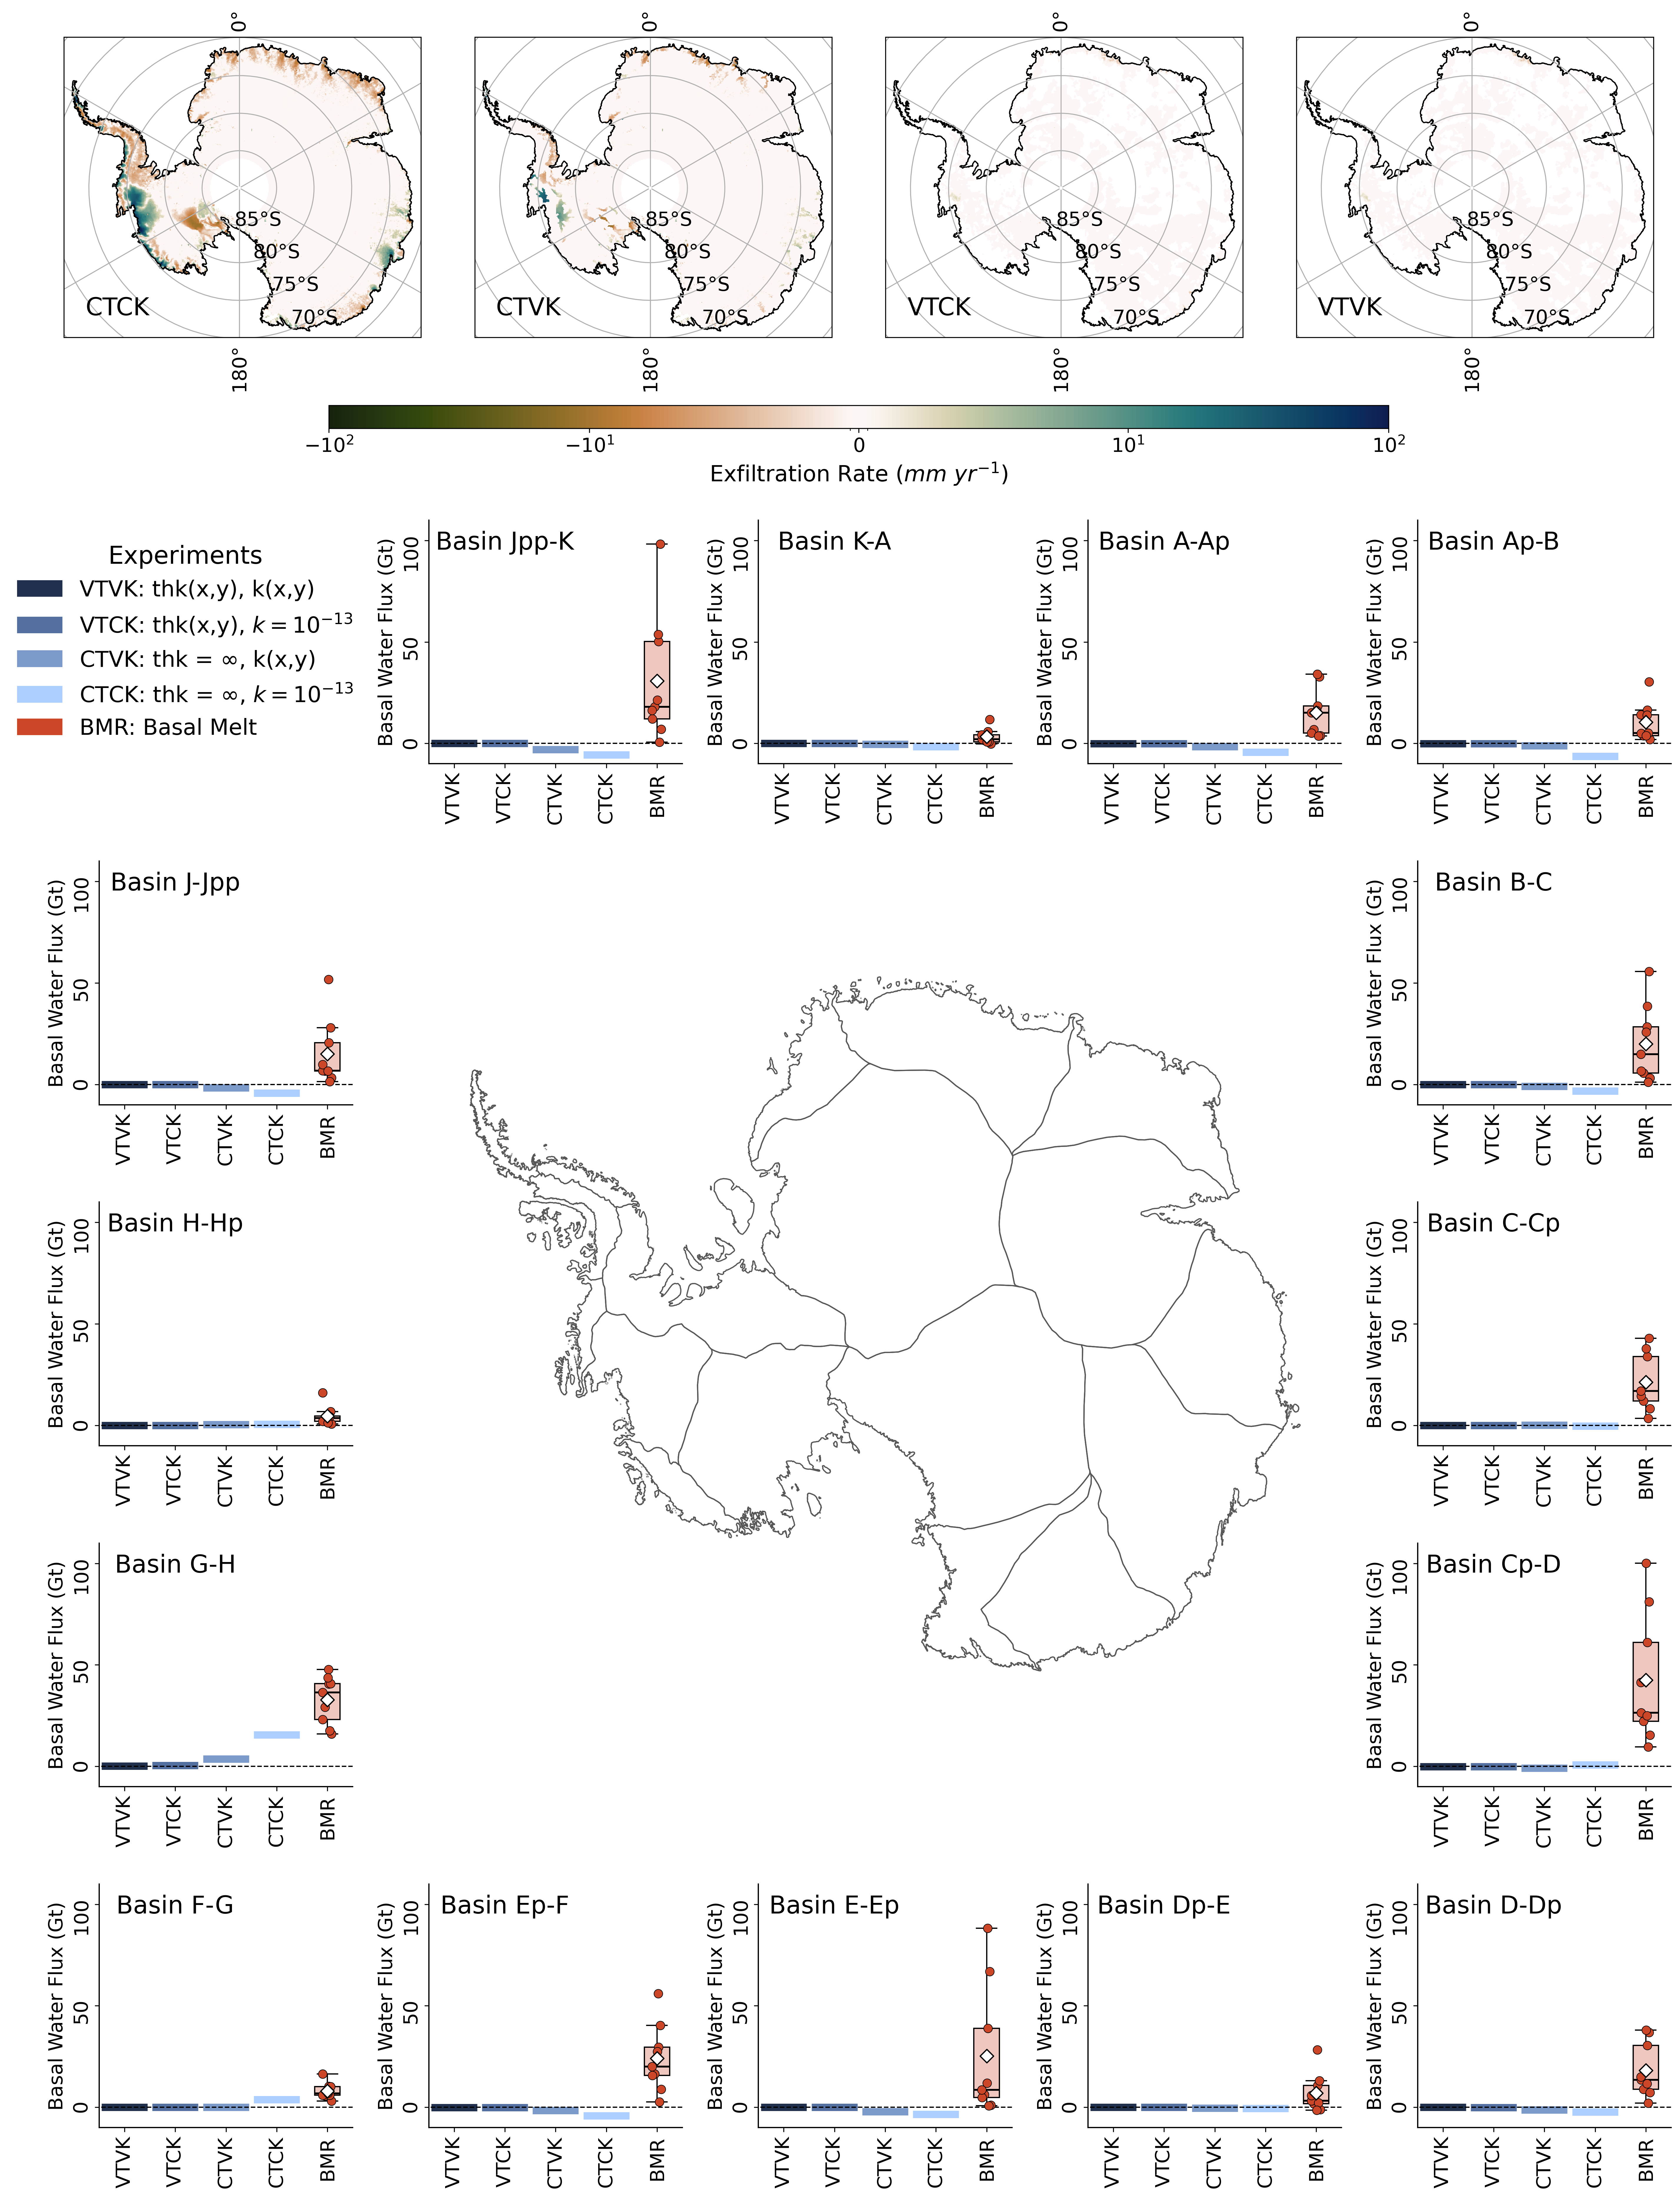

In [13]:
fig = plt.figure(figsize=(20,26), dpi=300)
spec_map = gridspec.GridSpec(1, 4, figure=fig,
                             left=0.05, right=0.95, top=0.97, bottom=0.80,
                             wspace=0.15)

spec_bar = gridspec.GridSpec(5, 5, figure=fig,
                             left=0.07, right=0.96, top=0.74, bottom=0.04,
                             wspace=0.30, hspace=0.40)

ax1 = fig.add_subplot(spec_map[0, 0], projection=projection)
ax1.set_extent([min(ATL15["x"])*1.05, max(ATL15["x"])*1.05, min(ATL15["y"])*1.05, max(ATL15["y"])*1.05], crs=ccrs.SouthPolarStereo()) 
p1 = ax1.pcolormesh(ATL15["x"], ATL15["y"], exfil_numerical['CTCK'][-1,:,:], cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03, vmin=-100, vmax=100))
scripps_gl.plot(ax = ax1, edgecolor="black",linewidth=1, facecolor="None")
gl = ax1.gridlines(draw_labels=True)
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
plt.title("CTCK", fontsize=20, y=0.05,x=0.15)

ax2 = fig.add_subplot(spec_map[0, 1], projection=projection)
ax2.set_extent([min(ATL15["x"])*1.05, max(ATL15["x"])*1.05, min(ATL15["y"])*1.05, max(ATL15["y"])*1.05], crs=ccrs.SouthPolarStereo()) 
p2 = ax2.pcolormesh(ATL15["x"], ATL15["y"], exfil_numerical['CTVK'][-1,:,:], cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03, vmin=-100, vmax=100))
scripps_gl.plot(ax = ax2, edgecolor="black",linewidth=1, facecolor="None")
gl = ax2.gridlines(draw_labels=True)
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
plt.title("CTVK", fontsize=20, y=0.05,x=0.15)

ax3 = fig.add_subplot(spec_map[0, 2], projection=projection)
ax3.set_extent([min(ATL15["x"])*1.05, max(ATL15["x"])*1.05, min(ATL15["y"])*1.05, max(ATL15["y"])*1.05], crs=ccrs.SouthPolarStereo()) 
p3 = ax3.pcolormesh(ATL15["x"], ATL15["y"], exfil_numerical['VTCK'][-1,:,:], cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03, vmin=-100, vmax=100))
scripps_gl.plot(ax = ax3, edgecolor="black",linewidth=1, facecolor="None")
gl = ax3.gridlines(draw_labels=True)
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
plt.title("VTCK", fontsize=20, y=0.05,x=0.15)

ax4 = fig.add_subplot(spec_map[0, 3], projection=projection)
ax4.set_extent([min(ATL15["x"])*1.05, max(ATL15["x"])*1.05, min(ATL15["y"])*1.05, max(ATL15["y"])*1.05], crs=ccrs.SouthPolarStereo()) 
p4 = ax4.pcolormesh(ATL15["x"], ATL15["y"], exfil_numerical['VTVK'][-1,:,:], cmap=cmocean.cm.tarn,
                   norm=colors.SymLogNorm(linthresh=1.0, linscale=0.03, vmin=-100, vmax=100))
scripps_gl.plot(ax = ax4, edgecolor="black",linewidth=1, facecolor="None")
gl = ax4.gridlines(draw_labels=True)
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
plt.title("VTVK", fontsize=20, y=0.05,x=0.15)

cax = plt.axes([0.2, 0.78, 0.6, 0.01])
cb = plt.colorbar(p1, cax=cax, orientation='horizontal', ticks=[-100, -10, 0, 10, 100])
cb.ax.set_xlabel(r'Exfiltration Rate ($mm \ yr^{-1}$)', fontsize=18)
cb.ax.tick_params(labelsize=16)

# ## Big Figure

bar_color = ["#21314d", "#5470A1", "#7B9AC9", "#ADCFFF", "#CC4628"]
cat = ['VTVK','VTCK','CTVK','CTCK','BMR']
cat_legend = [r'VTVK: thk(x,y), k(x,y)',r'VTCK: thk(x,y), $k=10^{-13}$',r'CTVK: thk = $\infty$, k(x,y)',r'CTCK: thk = $\infty$, $k=10^{-13}$','BMR: Basal Melt']

def plot_boxjit(ax,bas):
    cumul_cthk_ck, cumul_cthk_vk, cumul_vthk_ck, cumul_vthk_vk, mean_bmr, min_bmr, max_bmr, all_interp_bmr = compute_basin_sums(bas)
    bmr_june2024 = np.interp(end_date_numeric.astype(float),annual_time_np.astype(float),mean_bmr)

    bmr_june2024_all = np.zeros(9)
    for i in range(9):
        bmr_june2024_all[i] = np.interp(end_date_numeric.astype(float),annual_time_np.astype(float),all_interp_bmr[i,:])

    val = [cumul_vthk_vk[-1],cumul_vthk_ck[-1],cumul_cthk_vk[-1],cumul_cthk_ck[-1]]
    ax.scatter([1,2,3,4], val, color=bar_color[:-1],marker="_",s = 1400,linewidth = 6)

    ax.boxplot(bmr_june2024_all,
               positions=[5],
               patch_artist=True,
               widths = 0.5,
               showfliers=False,
               boxprops=dict(facecolor=to_rgba("#CC4628", 0.3)),
               medianprops=dict(color='k',linestyle='-',linewidth=1.5),
               capwidths=0.4)

    rng = np.random.default_rng(0)
    jit = rng.uniform(-0.1, 0.1, size=bmr_june2024_all.size)
    ax.scatter(5 + jit, bmr_june2024_all, s=50, color=bar_color[-1],
            edgecolor='k', linewidth=0.5, zorder=3)
    ax.scatter(5,bmr_june2024,s=60,marker="D",color="#FFFFFF",edgecolor='k', linewidth=1.0, zorder=3)
    ax.hlines(0,-1,6,linestyles='dashed',color='k',linewidth=1.0)

    ax.set_xticks([1,2,3,4,5])
    ax.set_xticklabels(cat, rotation=90)
    ax.tick_params(axis='both', which='major', labelsize=16,rotation=90)
    ax.set_title('Basin '+ IMBIE.loc[bas].Subregion, fontsize = 20, y = 0.85,x=0.3)
    ax.set_ylabel("Basal Water Flux (Gt)", fontsize = 16)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.locator_params(axis='y', nbins=4) 
    ax.spines['bottom'].set_linewidth(1)
    ax.spines['left'].set_linewidth(1)
    ax.set_ylim([-10,110])
    ax.set_xlim([0.5,5.5])
    print(bmr_june2024)
    gw_frac = cumul_vthk_vk[-1]/(cumul_vthk_vk[-1] + bmr_june2024)
    print('Basin '+ str(IMBIE.loc[bas].Subregion) + " : " + str(gw_frac*100) + "%")


ax_AA = fig.add_subplot(spec_bar[1:4, 1:4])
IMBIE.plot(ax=ax_AA, color="none", edgecolor='#575757',facecolor="none",linewidth=1)

plt.axis('off')

ax_jppk = fig.add_subplot(spec_bar[0, 1])
plot_boxjit(ax_jppk,8)

ax_ka = fig.add_subplot(spec_bar[0, 2])
plot_boxjit(ax_ka,13)

ax_aap = fig.add_subplot(spec_bar[0, 3])
plot_boxjit(ax_aap,7)

ax_apb = fig.add_subplot(spec_bar[0, 4])
plot_boxjit(ax_apb,11)

ax_bc = fig.add_subplot(spec_bar[1, 4])
plot_boxjit(ax_bc,6)

ax_ccp = fig.add_subplot(spec_bar[2, 4])
plot_boxjit(ax_ccp,12)

ax_cpd = fig.add_subplot(spec_bar[3, 4])
plot_boxjit(ax_cpd,5)

ax_ddp = fig.add_subplot(spec_bar[4, 4])
plot_boxjit(ax_ddp,4)

ax_dpe = fig.add_subplot(spec_bar[4, 3])
plot_boxjit(ax_dpe,10)

ax_eep = fig.add_subplot(spec_bar[4, 2])
plot_boxjit(ax_eep,3)

ax_epf = fig.add_subplot(spec_bar[4, 1])
plot_boxjit(ax_epf,18)

ax_fg = fig.add_subplot(spec_bar[4, 0])
plot_boxjit(ax_fg,2)

ax_gh = fig.add_subplot(spec_bar[3, 0])
plot_boxjit(ax_gh,9)

ax_hhp = fig.add_subplot(spec_bar[2, 0])
plot_boxjit(ax_hhp,1)

ax_jjpp = fig.add_subplot(spec_bar[1, 0])
plot_boxjit(ax_jjpp,14)

ax_legend = fig.add_subplot(spec_bar[0, 0])
ax_legend.axis("off")

handles = [mpatches.Patch(color=c, label=label) 
           for c, label in zip(bar_color, cat_legend)]

leg = ax_legend.legend(
    handles, cat_legend,
    loc="center left",
    bbox_to_anchor=(-0.4, 0.5),
    frameon=False,
    fontsize=18,
    title_fontsize=20,
    title="Experiments")

plt.savefig("fig2_oct15unann.png")

